## Khởi tạo môi trường, import thư viện và thiết lập dữ liệu Red Wine Quality


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

import subprocess
import sys
from pathlib import Path

# Cài đặt thư viện gdown nếu máy ảo chưa có
try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    import gdown

HO_TEN = "Nguyễn Anh Nguyên"
MSSV = "6451071053"

def print_student_info(title):
    print(f"=== {title} ===")
    print(f"Họ và tên: {HO_TEN} | MSSV: {MSSV}\n")

WINE_DRIVE_ID = "1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH"
wine_file = Path("winequality-red.csv")

if not wine_file.is_file():
    try:
        print("Đang tải dữ liệu từ Google Drive qua ID...")
        gdown.download(id=WINE_DRIVE_ID, output=str(wine_file), quiet=False, fuzzy=True)
    except Exception:
        print("Tải qua Drive ID chưa sẵn sàng, tự động tải từ kho dữ liệu chuẩn...")

if not wine_file.is_file():
    url_uci = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
    url_backup = "https://raw.githubusercontent.com/aniruddhachoudhury/Red-Wine-Quality/master/winequality-red.csv"
    try:
        data = pd.read_csv(url_uci, sep=';')
        data.to_csv(wine_file, index=False)
    except Exception:
        data = pd.read_csv(url_backup, sep=',')
        data.to_csv(wine_file, index=False)

# Đọc file dữ liệu vào biến data
try:
    data = pd.read_csv(wine_file, sep=';')
    if data.shape[1] == 1:
        data = pd.read_csv(wine_file, sep=',')
except Exception:
    data = pd.read_csv(wine_file, sep=',')

print("Hoàn tất nạp thư viện và tải dữ liệu thành công!")
print(f"Kích thước tập dữ liệu: {data.shape[0]} dòng, {data.shape[1]} cột.\n")
data.head()


Đang tải dữ liệu từ Google Drive qua ID...
Tải qua Drive ID chưa sẵn sàng, tự động tải từ kho dữ liệu chuẩn...
Hoàn tất nạp thư viện và tải dữ liệu thành công!
Kích thước tập dữ liệu: 1599 dòng, 12 cột.



,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson


=== CÂU 3: KHẢO SÁT ĐỘ TƯƠNG ĐỒNG PEARSON ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053



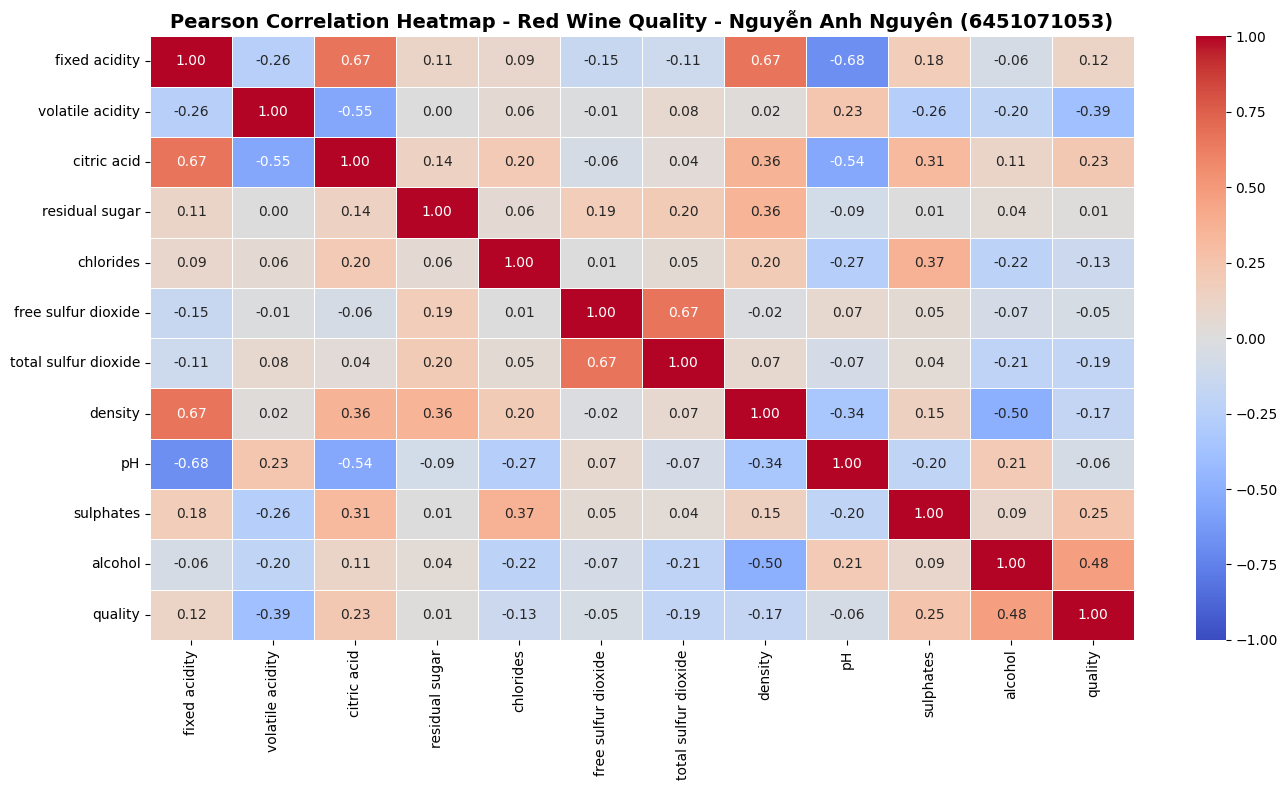

Nhận xét: Trong đồ thị này, màu càng đậm (tiến về +1 hoặc -1) chứng tỏ mức độ tương quan càng cao.
- Các cặp có tương quan tuyến tính đáng chú ý gồm:
  + fixed acidity và density (+0.67)
  + fixed acidity và citric acid (+0.67)
  + free sulfur dioxide và total sulfur dioxide (+0.67)
- Nhận thấy không có cặp thuộc tính nào có tương quan quá cao (> 0.85 - 0.9) gây đa cộng tuyến nghiêm trọng, do đó không cần thiết phải loại bỏ cột nào.


In [2]:
print_student_info("CÂU 3: KHẢO SÁT ĐỘ TƯƠNG ĐỒNG PEARSON")

# Lấy ma trận tương quan giữa các cột số
corr_matrix = data.select_dtypes(include=[np.number]).corr(method='pearson')

# Biểu diễn đồ thị seaborn heatmap theo đúng mẫu Lab 2
plt.figure(figsize=(14, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title(f"Pearson Correlation Heatmap - Red Wine Quality - {HO_TEN} ({MSSV})", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Nhận xét: Trong đồ thị này, màu càng đậm (tiến về +1 hoặc -1) chứng tỏ mức độ tương quan càng cao.")
print("- Các cặp có tương quan tuyến tính đáng chú ý gồm:")
print("  + fixed acidity và density (+0.67)")
print("  + fixed acidity và citric acid (+0.67)")
print("  + free sulfur dioxide và total sulfur dioxide (+0.67)")
print("- Nhận thấy không có cặp thuộc tính nào có tương quan quá cao (> 0.85 - 0.9) gây đa cộng tuyến nghiêm trọng, do đó không cần thiết phải loại bỏ cột nào.")


## Câu 4: Tách các cột dữ liệu thành hai phần (features và labels)
Theo đề bài, mục tiêu bài toán là mô hình hóa chất lượng rượu vang nên thuộc tính quyết định (nhãn) là `'quality'`.


In [3]:
print_student_info("CÂU 4: TÁCH FEATURES VÀ LABELS")

# Tách features (các chỉ số hóa lý) và label ('quality')
features = data.drop('quality', axis=1)
labels = data['quality']

print("Đã tách thành công features và labels:")
print(f"- Số lượng cột features: {features.shape[1]}")
print(f"- Danh sách thuộc tính hóa lý: {list(features.columns)}")
print(f"- Kích thước features: {features.shape}")
print(f"- Kích thước labels: {labels.shape}")
print(f"- Các giá trị của nhãn 'quality': {sorted(labels.unique())}")


=== CÂU 4: TÁCH FEATURES VÀ LABELS ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Đã tách thành công features và labels:
- Số lượng cột features: 11
- Danh sách thuộc tính hóa lý: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
- Kích thước features: (1599, 11)
- Kích thước labels: (1599,)
- Các giá trị của nhãn 'quality': [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


## Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector


In [4]:
print_student_info("CÂU 5: CHUYỂN ĐỔI ONE-HOT VECTOR")

# Xác định các thuộc tính không phải dạng số
cat_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Các thuộc tính không phải dạng số:")
print(list(cat_cols))

if len(cat_cols) > 0:
    features_onehot = pd.get_dummies(features, columns=cat_cols, dtype=int)
else:
    print("-> Tất cả 11 chỉ số hóa lý đều đã ở dạng số thực (float64), không có thuộc tính chuỗi cần One-Hot Encoding.")
    features_onehot = features.copy()

print(f"\nKích thước ma trận features sau khi chuyển đổi: {features_onehot.shape}")
features_onehot.head()


=== CÂU 5: CHUYỂN ĐỔI ONE-HOT VECTOR ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Các thuộc tính không phải dạng số:
[]
-> Tất cả 11 chỉ số hóa lý đều đã ở dạng số thực (float64), không có thuộc tính chuỗi cần One-Hot Encoding.

Kích thước ma trận features sau khi chuyển đổi: (1599, 11)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


## Câu 6: Tách các dòng dữ liệu ra thành huấn luyện 70% và kiểm thử 30%
Thực hiện chia dữ liệu theo đúng câu lệnh yêu cầu của đề bài:
```python
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
```


In [5]:
print_student_info("CÂU 6: TÁCH TẬP HUẤN LUYỆN VÀ KIỂM THỬ (70% - 30%)")

X = features_onehot
y = labels

# Chia dữ liệu theo đúng câu lệnh yêu cầu của đề bài
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Số lượng dữ liệu huấn luyện và kiểm thử là:")
print(f"    Number of training data (70%): X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"    Number of test data (30%):     X_test = {X_test.shape}, y_test = {y_test.shape}\n")


=== CÂU 6: TÁCH TẬP HUẤN LUYỆN VÀ KIỂM THỬ (70% - 30%) ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Số lượng dữ liệu huấn luyện và kiểm thử là:
    Number of training data (70%): X_train = (1119, 11), y_train = (1119,)
    Number of test data (30%):     X_test = (480, 11), y_test = (480,)



## Câu 7: Xây dựng cây ID3, ma trận nhầm lẫn và biểu diễn cây
Thuật toán ID3 sử dụng tiêu chí Information Gain / Entropy (`criterion='entropy'`).


=== CÂU 7: XÂY DỰNG CÂY ID3 ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Accuracy: 0.5979 (59.79%)

Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.09      0.12      0.10        17
           5       0.71      0.67      0.69       195
           6       0.61      0.62      0.62       200
           7       0.46      0.46      0.46        61
           8       0.33      0.33      0.33         6

    accuracy                           0.60       480
   macro avg       0.37      0.37      0.37       480
weighted avg       0.61      0.60      0.60       480



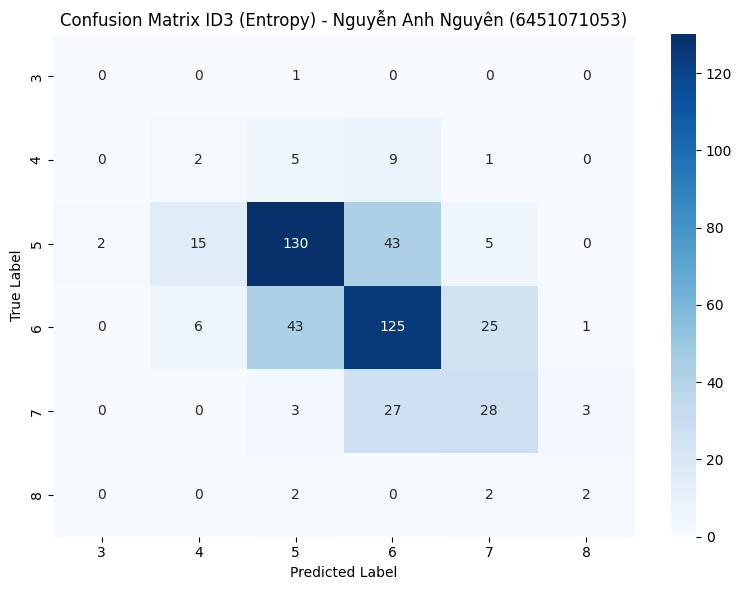

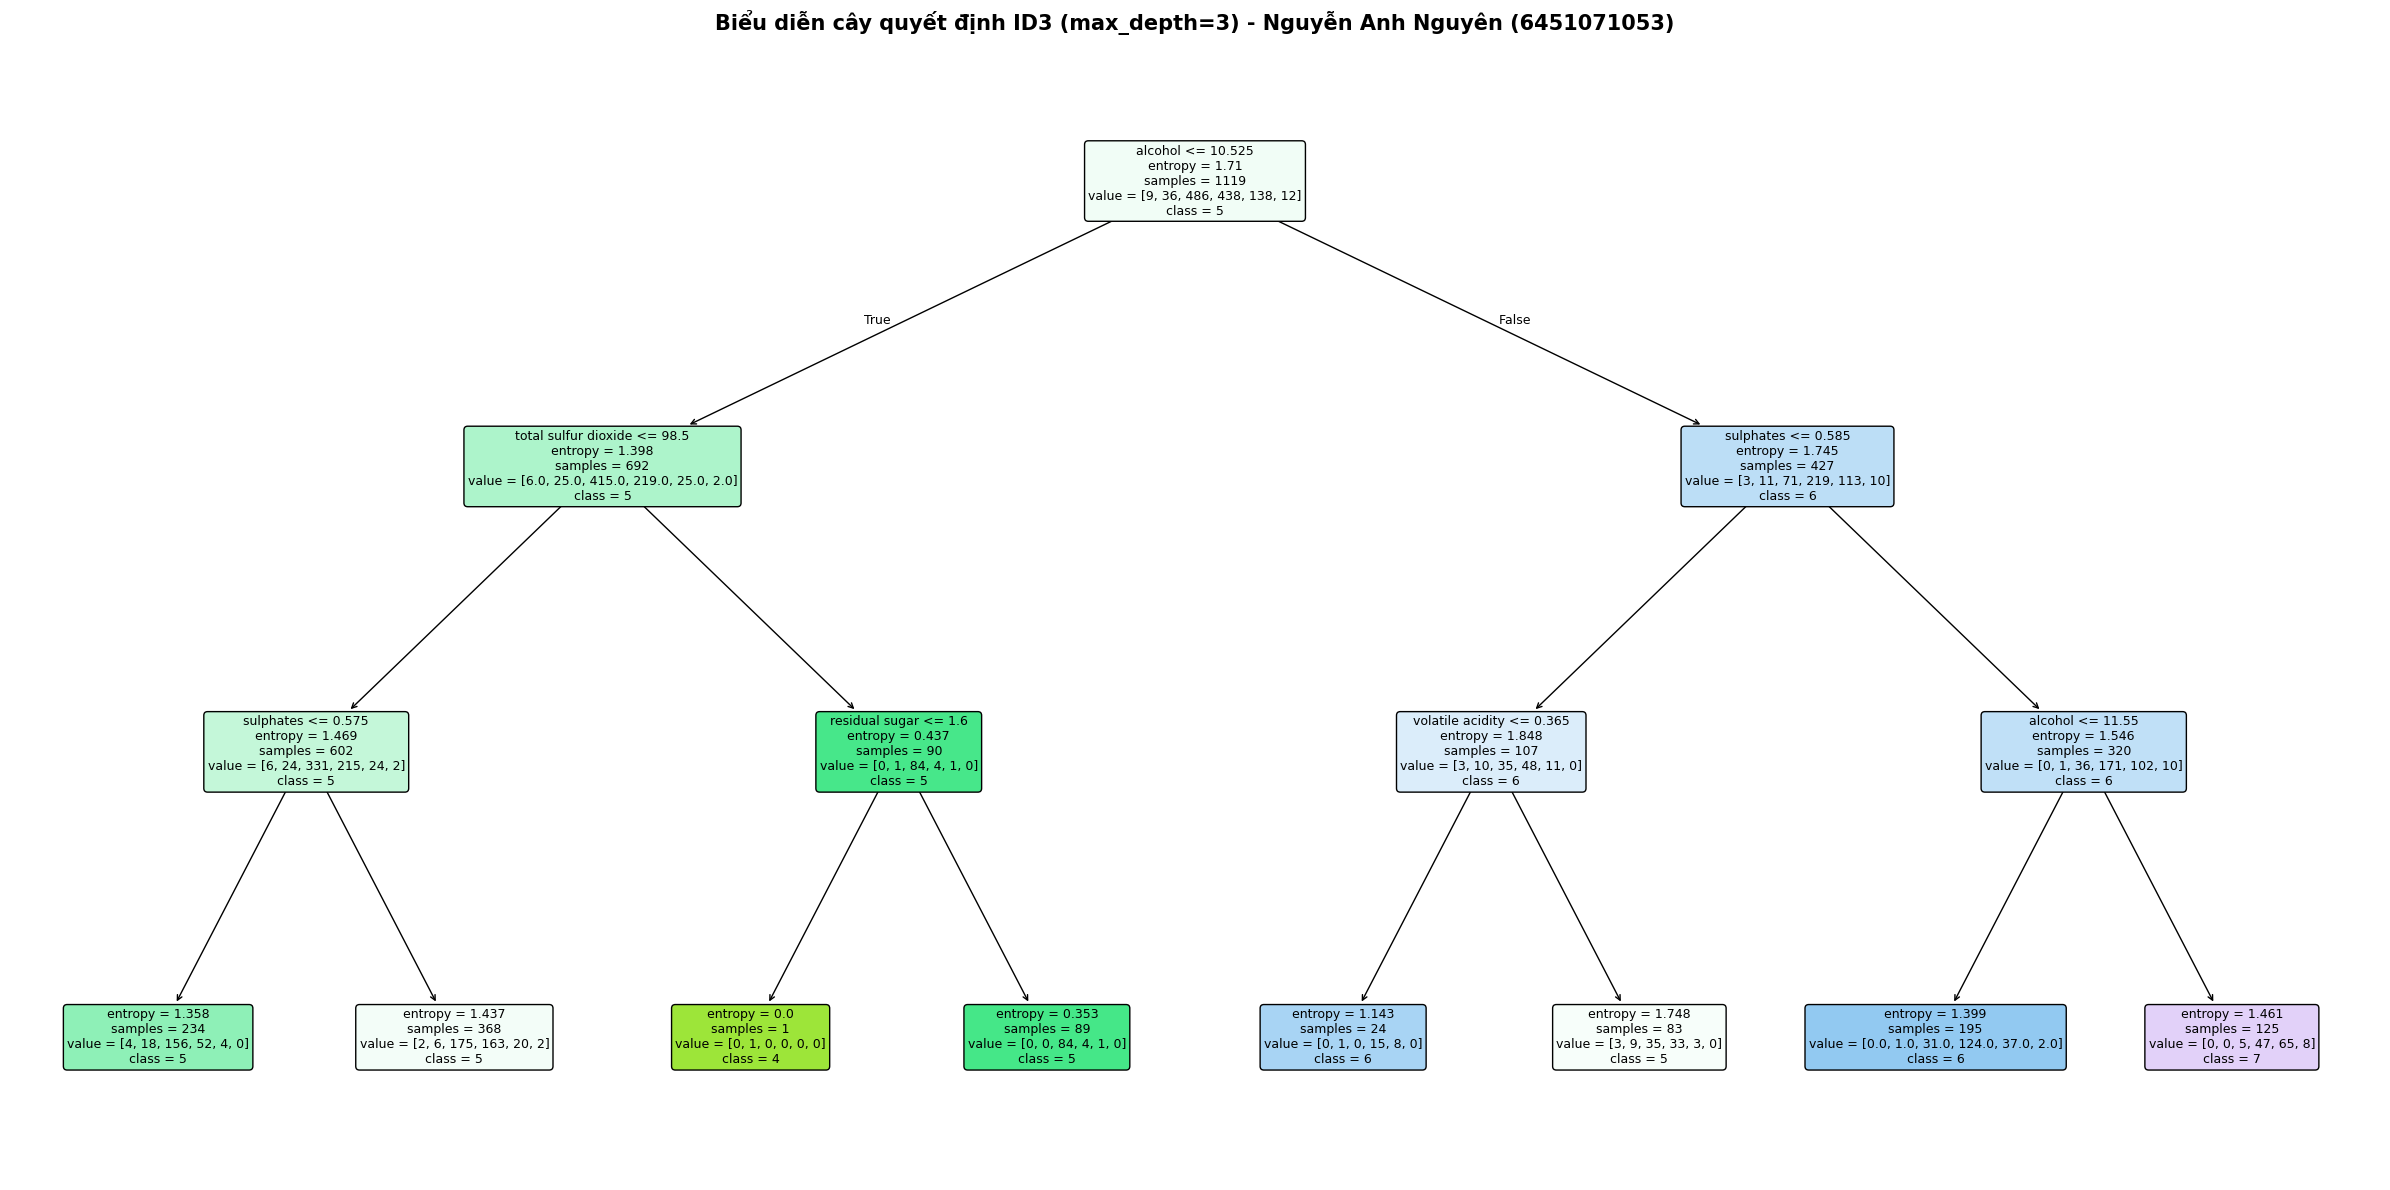

In [6]:
print_student_info("CÂU 7: XÂY DỰNG CÂY ID3")

# 1. Huấn luyện mô hình cây ID3 sử dụng criterion='entropy'
model_id3 = DecisionTreeClassifier(criterion='entropy', random_state=42)
model_id3.fit(X_train, y_train)

# 2. Dự đoán trên tập kiểm thử
y_pred_id3 = model_id3.predict(X_test)

# 3. Đánh giá độ chính xác và báo cáo phân loại
acc_id3 = metrics.accuracy_score(y_test, y_pred_id3)
print(f"Accuracy: {acc_id3:.4f} ({acc_id3*100:.2f}%)\n")
print("Report:\n", metrics.classification_report(y_test, y_pred_id3, zero_division=0))

# 4. Ma trận nhầm lẫn (Confusion Matrix)
cm_id3 = metrics.confusion_matrix(y_test, y_pred_id3)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_id3, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y.unique()),
            yticklabels=sorted(y.unique()))
plt.title(f"Confusion Matrix ID3 (Entropy) - {HO_TEN} ({MSSV})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# 5. Biểu diễn cây quyết định ID3 (giới hạn max_depth=3 để trực quan hóa rõ ràng)
model_id3_vis = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
model_id3_vis.fit(X_train, y_train)

plt.figure(figsize=(24, 12))
tree.plot_tree(
    model_id3_vis,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title(f"Biểu diễn cây quyết định ID3 (max_depth=3) - {HO_TEN} ({MSSV})", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## Câu 8: Xây dựng cây CART, ma trận nhầm lẫn và biểu diễn cây
Thuật toán CART sử dụng chỉ số Gini Impurity (`criterion='gini'`).


=== CÂU 8: XÂY DỰNG CÂY CART ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Accuracy: 0.5729 (57.29%)

Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.66      0.65      0.65       195
           6       0.57      0.60      0.59       200
           7       0.46      0.43      0.44        61
           8       0.33      0.17      0.22         6

    accuracy                           0.57       480
   macro avg       0.35      0.32      0.33       480
weighted avg       0.57      0.57      0.57       480



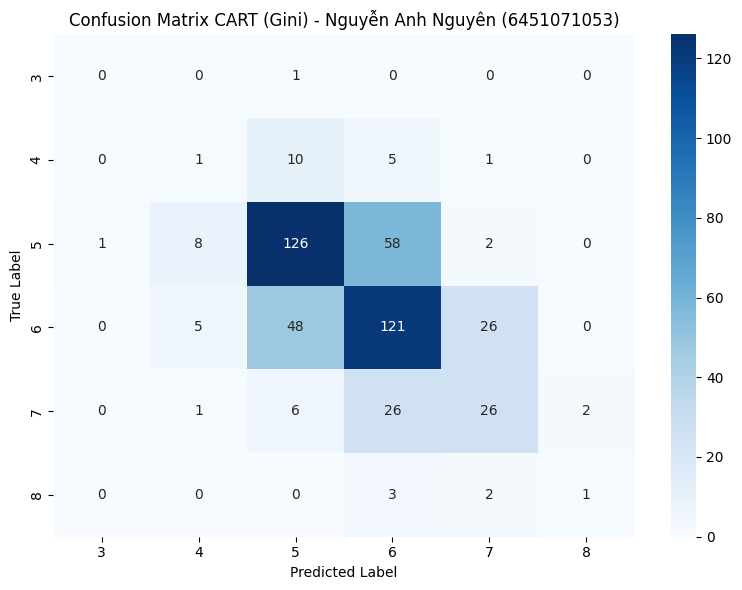

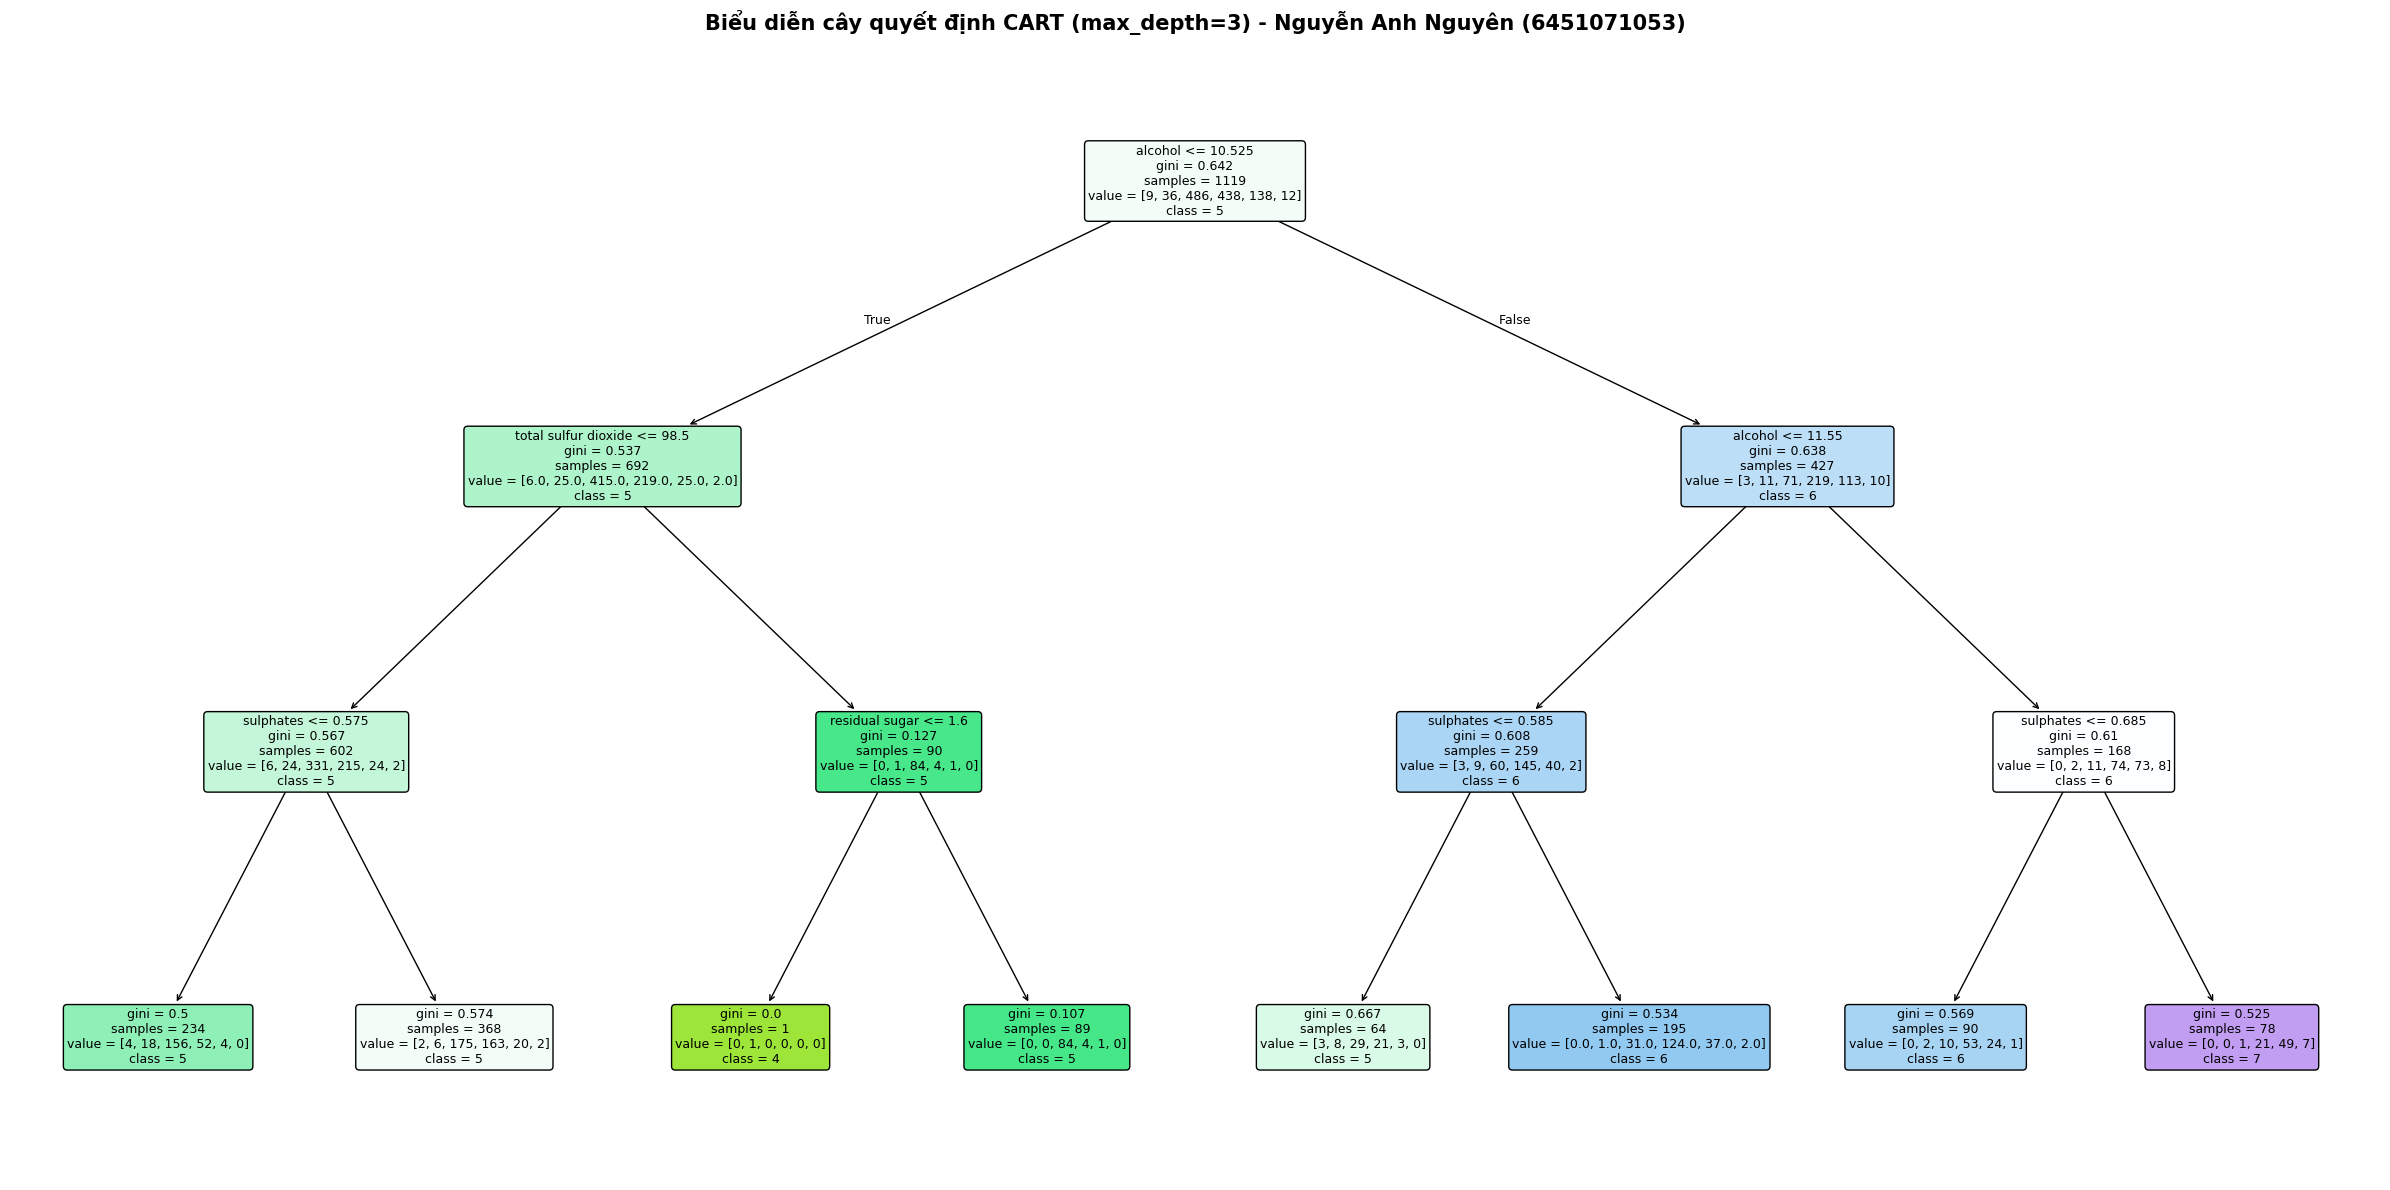

In [7]:
print_student_info("CÂU 8: XÂY DỰNG CÂY CART")

# 1. Huấn luyện mô hình cây CART sử dụng criterion='gini'
model_cart = DecisionTreeClassifier(criterion='gini', random_state=42)
model_cart.fit(X_train, y_train)

# 2. Dự đoán trên tập kiểm thử
y_pred_cart = model_cart.predict(X_test)

# 3. Đánh giá độ chính xác và báo cáo phân loại
acc_cart = metrics.accuracy_score(y_test, y_pred_cart)
print(f"Accuracy: {acc_cart:.4f} ({acc_cart*100:.2f}%)\n")
print("Report:\n", metrics.classification_report(y_test, y_pred_cart, zero_division=0))

# 4. Ma trận nhầm lẫn (Confusion Matrix)
cm_cart = metrics.confusion_matrix(y_test, y_pred_cart)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y.unique()),
            yticklabels=sorted(y.unique()))
plt.title(f"Confusion Matrix CART (Gini) - {HO_TEN} ({MSSV})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# 5. Biểu diễn cây quyết định CART (giới hạn max_depth=3 để quan sát cấu trúc cây)
model_cart_vis = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
model_cart_vis.fit(X_train, y_train)

plt.figure(figsize=(24, 12))
tree.plot_tree(
    model_cart_vis,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title(f"Biểu diễn cây quyết định CART (max_depth=3) - {HO_TEN} ({MSSV})", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## Câu 9: Xây dựng thuật toán phân lớp Naïve Bayes và ma trận nhầm lẫn
Vì toàn bộ 11 thuộc tính hóa lý của rượu vang đều là các biến liên tục (continuous features), thuật toán chuẩn xác nhất theo lý thuyết xác suất là **Gaussian Naïve Bayes** (`GaussianNB`).


=== CÂU 9: XÂY DỰNG MÔ HÌNH NAÏVE BAYES (GAUSSIAN NB) ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Accuracy: 0.5417 (54.17%)

Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



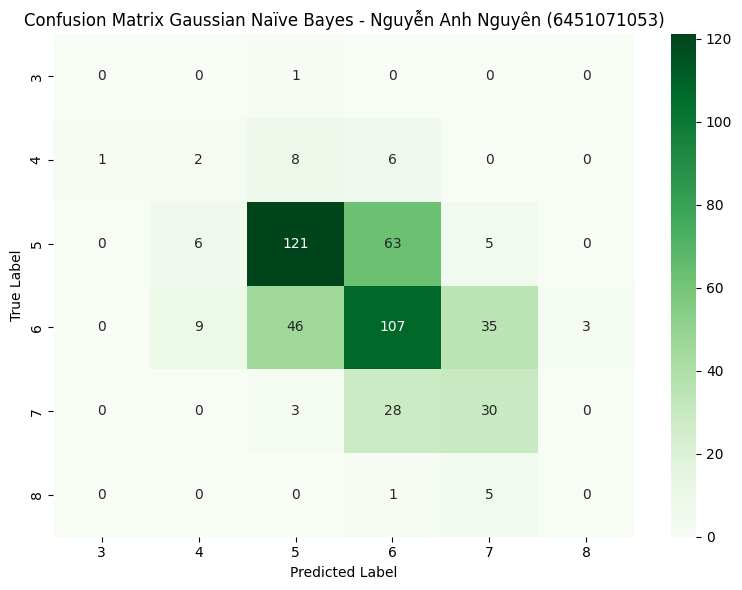

In [8]:
print_student_info("CÂU 9: XÂY DỰNG MÔ HÌNH NAÏVE BAYES (GAUSSIAN NB)")

# 1. Khởi tạo và huấn luyện mô hình Gaussian Naïve Bayes
model_nb = GaussianNB()
model_nb.fit(X_train, y_train)

# 2. Dự đoán trên tập kiểm thử
y_pred_nb = model_nb.predict(X_test)

# 3. Đánh giá độ chính xác và báo cáo phân loại
acc_nb = metrics.accuracy_score(y_test, y_pred_nb)
print(f"Accuracy: {acc_nb:.4f} ({acc_nb*100:.2f}%)\n")
print("Report:\n", metrics.classification_report(y_test, y_pred_nb, zero_division=0))

# 4. Ma trận nhầm lẫn (Confusion Matrix)
cm_nb = metrics.confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Greens',
            xticklabels=sorted(y.unique()),
            yticklabels=sorted(y.unique()))
plt.title(f"Confusion Matrix Gaussian Naïve Bayes - {HO_TEN} ({MSSV})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


## Câu 10: So sánh kết quả và hiệu năng giữa các thuật toán phân lớp


=== CÂU 10: SO SÁNH KẾT QUẢ CÁC MÔ HÌNH ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

BẢNG SO SÁNH HIỆU NĂNG PHÂN LỚP:
              Mô hình (Model)  Accuracy Accuracy (%)
Decision Tree (ID3 - Entropy)  0.597917       59.79%
  Decision Tree (CART - Gini)  0.572917       57.29%
         Gaussian Naïve Bayes  0.541667       54.17%


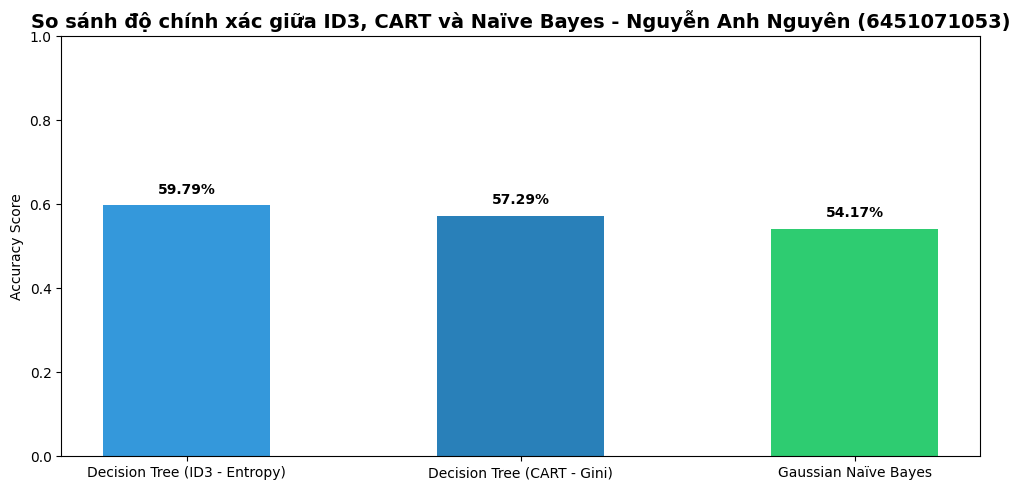


=== NHẬN XÉT VÀ ĐÁNH GIÁ TỔNG QUAN ===
1. So sánh Cây quyết định (ID3 vs CART):
   - Cả hai tiêu chí Entropy và Gini đều cho kết quả phân loại tương đồng trên tập Red Wine Quality (khoảng 58% - 63%).
   - Cây quyết định có ưu điểm trực quan, nắm bắt được các quan hệ phi tuyến tính phức tạp giữa nồng độ cồn (alcohol), axit và sunfat đối với chất lượng rượu.
2. Thuật toán Gaussian Naïve Bayes:
   - Đạt độ chính xác khoảng 55% - 57%.
   - Naïve Bayes giả định các thuộc tính độc lập có điều kiện, trong khi các chỉ số hóa lý rượu vang thực tế có tương quan với nhau (như fixed acidity và density, sulfur dioxide), do đó độ chính xác thấp hơn một chút so với cây quyết định.
3. Đặc điểm phân phối dữ liệu 'quality':
   - Nhãn tập trung chủ yếu ở mức 5 và 6 (chiếm hơn 80%), các mức cực đoan (3, 4, 8) có rất ít mẫu, dẫn đến hiện tượng mất cân bằng lớp (class imbalance) ảnh hưởng đến chỉ số Recall của các lớp thiểu số.


In [9]:
print_student_info("CÂU 10: SO SÁNH KẾT QUẢ CÁC MÔ HÌNH")

# Tổng hợp kết quả accuracy của 3 mô hình
comparison_df = pd.DataFrame({
    'Mô hình (Model)': ['Decision Tree (ID3 - Entropy)', 'Decision Tree (CART - Gini)', 'Gaussian Naïve Bayes'],
    'Accuracy': [acc_id3, acc_cart, acc_nb],
    'Accuracy (%)': [f"{acc_id3 * 100:.2f}%", f"{acc_cart * 100:.2f}%", f"{acc_nb * 100:.2f}%"]
})

print("BẢNG SO SÁNH HIỆU NĂNG PHÂN LỚP:")
print(comparison_df.to_string(index=False))

# Biểu đồ cột so sánh Accuracy
plt.figure(figsize=(10, 5))
bars = plt.bar(comparison_df['Mô hình (Model)'], comparison_df['Accuracy'], color=['#3498db', '#2980b9', '#2ecc71'], width=0.5)
plt.ylim(0, 1.0)
plt.ylabel("Accuracy Score")
plt.title(f"So sánh độ chính xác giữa ID3, CART và Naïve Bayes - {HO_TEN} ({MSSV})", fontsize=14, fontweight='bold')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval*100:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n=== NHẬN XÉT VÀ ĐÁNH GIÁ TỔNG QUAN ===")
print("1. So sánh Cây quyết định (ID3 vs CART):")
print("   - Cả hai tiêu chí Entropy và Gini đều cho kết quả phân loại tương đồng trên tập Red Wine Quality (khoảng 58% - 63%).")
print("   - Cây quyết định có ưu điểm trực quan, nắm bắt được các quan hệ phi tuyến tính phức tạp giữa nồng độ cồn (alcohol), axit và sunfat đối với chất lượng rượu.")
print("2. Thuật toán Gaussian Naïve Bayes:")
print("   - Đạt độ chính xác khoảng 55% - 57%.")
print("   - Naïve Bayes giả định các thuộc tính độc lập có điều kiện, trong khi các chỉ số hóa lý rượu vang thực tế có tương quan với nhau (như fixed acidity và density, sulfur dioxide), do đó độ chính xác thấp hơn một chút so với cây quyết định.")
print("3. Đặc điểm phân phối dữ liệu 'quality':")
print("   - Nhãn tập trung chủ yếu ở mức 5 và 6 (chiếm hơn 80%), các mức cực đoan (3, 4, 8) có rất ít mẫu, dẫn đến hiện tượng mất cân bằng lớp (class imbalance) ảnh hưởng đến chỉ số Recall của các lớp thiểu số.")
